# CardioIA · CNN e Transfer Learning
As duas abordagens são avaliadas nos mesmos exames reservados. A seleção da época usa Average Precision na validação, e o limiar maximiza o F1 positivo nesse mesmo conjunto.

In [1]:
from pathlib import Path
import subprocess
import sys

raiz = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "fase4/src").is_dir()), None)
if raiz is None:
    raiz = Path.cwd() / "cardioia-fase4-revisao"
    if not (raiz / "fase4/src").is_dir():
        subprocess.run(["git", "clone", "--branch", "fase4", "--depth", "1",
                        "https://github.com/marcus-vlgarcia/cardioia.git", str(raiz)], check=True)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r",
                    str(raiz / "fase4/requirements.txt")], check=True)
sys.path.insert(0, str(raiz / "fase4/src"))


In [2]:
import inspect
from modelos import cnn_simples, ResNetAdaptada
from treinar import executar, ajustar
print(inspect.getsource(cnn_simples))
print(inspect.getsource(ResNetAdaptada))

def cnn_simples():
    return nn.Sequential(
        nn.Conv2d(3, 16, 3, padding=1), nn.BatchNorm2d(16), nn.ReLU(), nn.MaxPool2d(2),
        nn.Conv2d(16, 32, 3, padding=1), nn.BatchNorm2d(32), nn.ReLU(), nn.MaxPool2d(2),
        nn.Conv2d(32, 64, 3, padding=1), nn.BatchNorm2d(64), nn.ReLU(), nn.MaxPool2d(2),
        nn.Flatten(), nn.Dropout(0.25), nn.Linear(64 * 7 * 7, 1),
    )

class ResNetAdaptada(nn.Module):
    """Mantém os primeiros blocos fixos e ajusta o último bloco e a saída."""

    def __init__(self):
        super().__init__()
        self.extrator = extrator_resnet()
        self.extrator.layer4.requires_grad_(True)
        self.saida = classificador_resnet()

    def train(self, mode=True):
        super().train(mode)
        self.extrator.eval()
        self.extrator.layer4.train(mode)
        return self

    def forward(self, x):
        return self.saida(self.extrator(normalizar_imagenet(x)))

    def estado_adaptado(self):
        return {"layer4": self.extrator.la

In [3]:
print(inspect.getsource(ajustar))

def ajustar(modelo, loaders, device, nome, epocas=None):
    epocas = EPOCAS[nome] if epocas is None else epocas
    if nome == "cnn":
        grupos = [{"params": modelo.parameters(), "lr": 0.001}]
    else:
        grupos = [{"params": modelo.extrator.layer4.parameters(), "lr": 0.0002},
                  {"params": modelo.saida.parameters(), "lr": 0.001}]
    otimizador = torch.optim.AdamW(grupos)
    agenda = torch.optim.lr_scheduler.CosineAnnealingLR(otimizador, T_max=epocas)
    rng = random.Random(SEMENTE)
    perda = nn.BCEWithLogitsLoss()
    melhor, estado, historico = -1, None, []
    for epoca in range(epocas):
        modelo.train()
        total = 0.0
        for x, y in loaders["train"]:
            otimizador.zero_grad()
            erro = perda(modelo(aumentar(x.to(device), rng)).flatten(), y.to(device, dtype=torch.float32))
            erro.backward()
            otimizador.step()
            total += erro.item() * len(y)
        agenda.step()
        scores, y = avali

In [4]:
import json
from dados import RESULTADOS
REPETIR_TREINO = False
resultado = executar() if REPETIR_TREINO else json.loads((RESULTADOS / "metricas.json").read_text())

In [5]:
import pandas as pd
linhas = []
for nome, m in resultado["modelos"].items():
    for classe, descricao in [("0", "Sem rótulo"), ("1", "Com rótulo")]:
        c = m["relatorio"][classe]
        linhas.append({"Modelo": nome, "Classe": descricao, "Acurácia": m["acuracia"],
                       "Precisão": c["precision"], "Recall": c["recall"], "F1": c["f1-score"],
                       "Amostras": c["support"], "AP": m["average_precision"], "Limiar": m["limiar"]})
display(pd.DataFrame(linhas).round(3))

,Modelo,Classe,Acurácia,Precisão,Recall,F1,Amostras,AP,Limiar
0,cnn,Sem rótulo,0.949,0.982,0.966,0.974,14040.0,0.212,0.508
1,cnn,Com rótulo,0.949,0.226,0.360,0.278,392.0,0.212,0.508
2,resnet18,Sem rótulo,0.924,0.980,0.940,0.960,14040.0,0.116,0.574
3,resnet18,Com rótulo,0.924,0.133,0.327,0.189,392.0,0.116,0.574


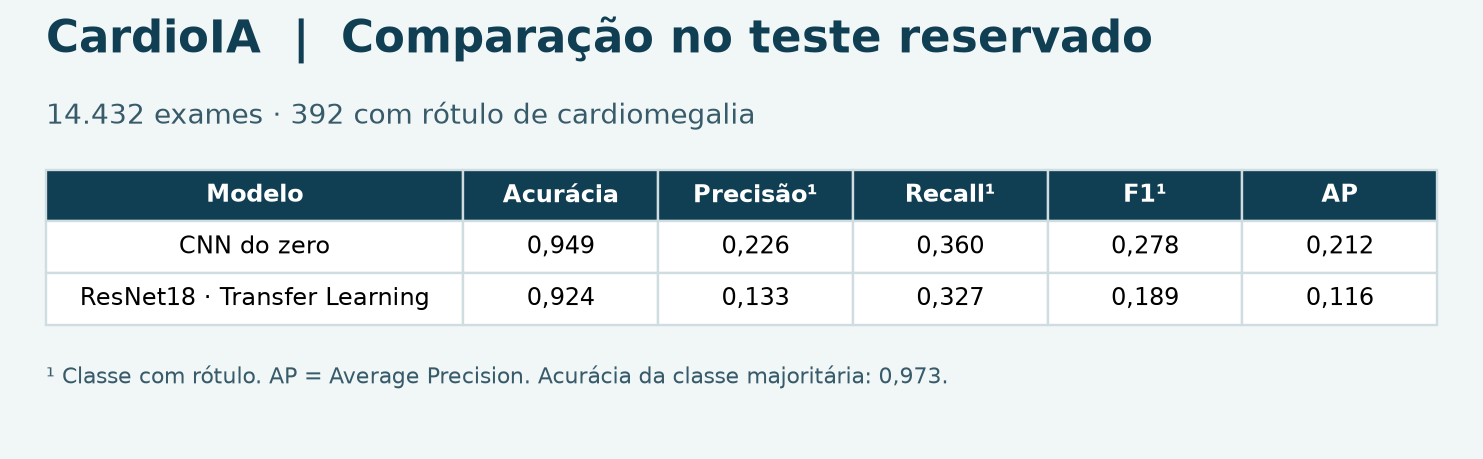

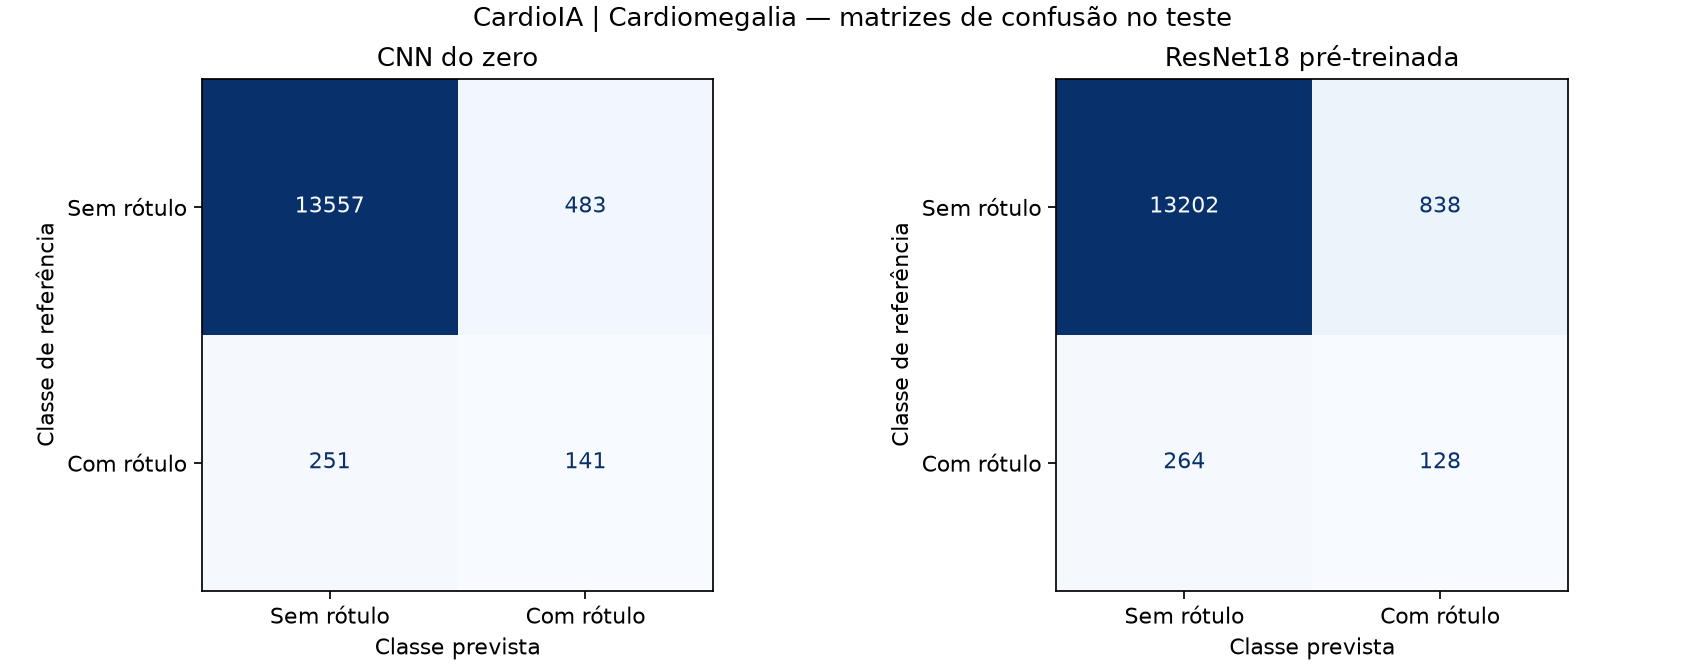

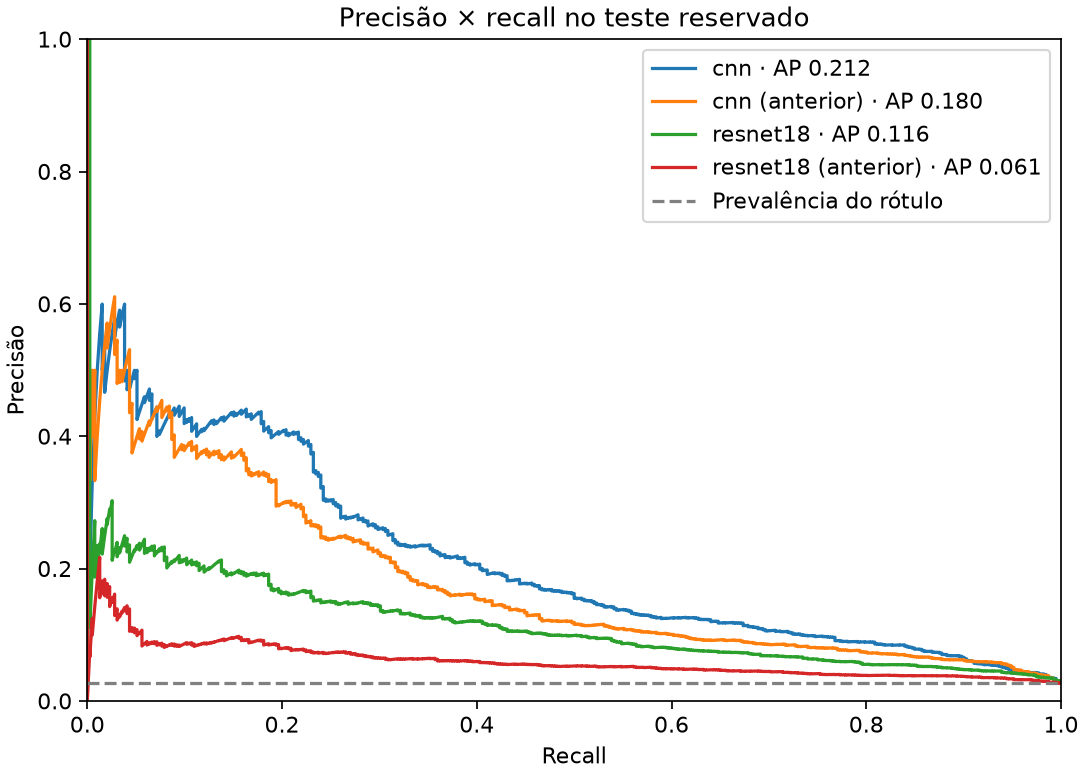

In [6]:
from IPython.display import Image, display
for figura in ("metricas.png", "matrizes_confusao.png", "curva_precisao_recall.png"):
    display(Image(filename=str(RESULTADOS / figura)))

In [7]:
comparacao = []
for versao in ["referencia_cb3cc82", "modelos"]:
    for nome, m in resultado[versao].items():
        comparacao.append({"Versão": "Revisada" if versao == "modelos" else "Inicial",
                           "Modelo": nome, "Acurácia": m["acuracia"],
                           "Acurácia balanceada": m["acuracia_balanceada"],
                           "Recall positivo": m["relatorio"]["1"]["recall"],
                           "F1 positivo": m["relatorio"]["1"]["f1-score"], "AP": m["average_precision"]})
display(pd.DataFrame(comparacao).round(3))

,Versão,Modelo,Acurácia,Acurácia balanceada,Recall positivo,F1 positivo,AP
0,Inicial,cnn,0.954,0.634,0.296,0.257,0.180
1,Inicial,resnet18,0.928,0.565,0.181,0.120,0.061
2,Revisada,cnn,0.949,0.663,0.360,0.278,0.212
3,Revisada,resnet18,0.924,0.633,0.327,0.189,0.116


A primeira comparação usou os mesmos exames, inéditos à época. A seleção da época e do limiar usou a validação.

A acurácia deve ser lida junto com a matriz de confusão e o F1 da classe positiva. O teste contém muitos exames sem o rótulo, então acertar a classe majoritária pode produzir acurácia alta mesmo quando a identificação dos positivos é ruim.

## Complemento · Mais negativos e auditoria por paciente

O índice oficial do MedMNIST permite agrupar exames de uma mesma pessoa. Retiramos do teste os exames do paciente que também aparecia na validação. A CNN candidata recebe oito exemplos negativos por positivo, contra quatro na CNN de referência. A escolha entre as duas usa a AP na validação. O teste abaixo é um recorte da avaliação anterior e serve para comparação retrospectiva. Os intervalos da diferença são obtidos por reamostragem pareada de pacientes.

,exames,positivos,pacientes
train,17550,1950,8718
val,7997,179,2527
test,14396,391,4776


Escolha pela validação: candidata


,AP na validação
referencia,0.176158
candidata,0.184288


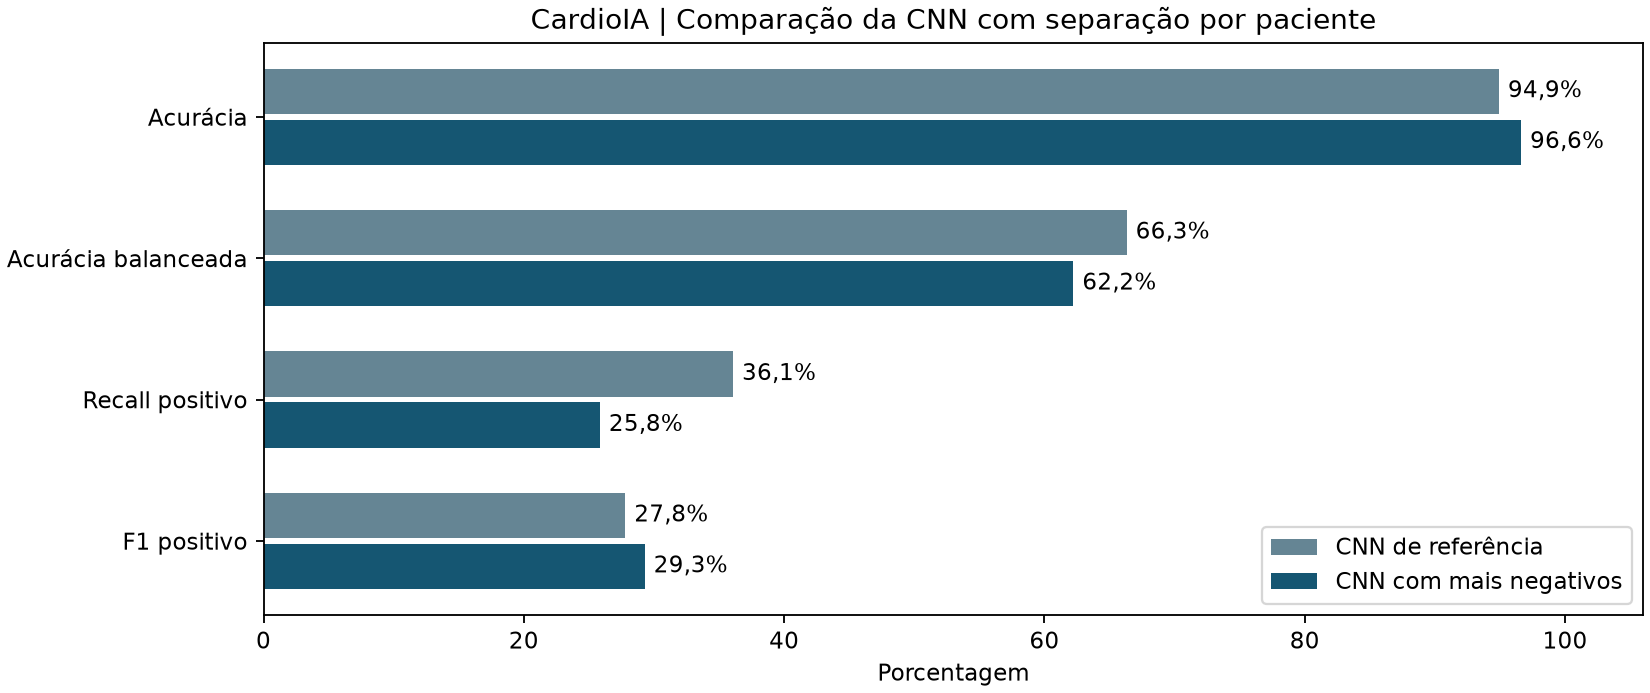

In [8]:
from evidencia_cnn import executar as gerar_evidencia_cnn
from comparar_cnn import executar as comparar_cnn

REPETIR_COMPARACAO = False
if REPETIR_COMPARACAO:
    comparar_cnn()
    gerar_evidencia_cnn()

auditoria = json.loads((RESULTADOS / "comparacao_cnn.json").read_text())
display(pd.DataFrame(auditoria["auditoria"]["particoes"]).T)
print("Escolha pela validação:", auditoria["escolha_validacao"])
display(pd.Series(auditoria["ap_validacao"], name="AP na validação").to_frame())
display(Image(filename=str(RESULTADOS / "comparacao_cnn.png")))

In [9]:
diferencas = pd.DataFrame.from_dict(auditoria["ic95_delta_bootstrap_por_paciente"],
                                     orient="index", columns=["Limite inferior", "Limite superior"])
display((100 * diferencas).round(2).rename_axis("Diferença candidata − referência (p.p.)"))

,Limite inferior,Limite superior
Diferença candidata − referência (p.p.),,
acuracia,1.36,2.03
acuracia_balanceada,-5.95,-2.36
recall_positivo,-14.06,-6.80
f1_positivo,-2.12,4.85
